In [10]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from pathlib import Path
from rasterio.merge import merge
import numpy as np
from rasterio.windows import from_bounds
from shapely.geometry import box
from rasterio.plot import plotting_extent
from sklearn.neighbors import NearestNeighbors
from shapely.geometry import Polygon, MultiPolygon
from shapely.ops import triangulate
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

In [11]:
# NYC Farmers Markets
markets_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "8vwk-6iz2/export.csv?accessType=DOWNLOAD"
)

markets_df = pd.read_csv(markets_url)
print(markets_df.columns.tolist())
print(markets_df.head())

['Year', 'Market Name', 'Borough', 'Street Address', 'Community District', 'Latitude', 'Longitude', 'Days of Operation', 'Hours of Operations', 'Season Dates', 'Accepts EBT', 'Open Year-Round', 'Stellar Cooking Demonstrations']
   Year                      Market Name    Borough  \
0  2025         175th Street Greenmarket  Manhattan   
1  2025  4th Ave Sunset Park Greenmarket   Brooklyn   
2  2025          57th Street Greenmarket  Manhattan   
3  2025          79th Street Greenmarket  Manhattan   
4  2025  7th Ave Sunset Park Greenmarket   Brooklyn   

                                Street Address  Community District   Latitude  \
0  W. 175th St. bet. Wadsworth Ave. & Broadway               112.0  40.845948   
1                            4th Ave. 60th St.               307.0  40.647975   
2                         57th St. & 10th Ave.               104.0  40.769117   
3                     79th St. & Columbus Ave.               107.0  40.782295   
4                          7th Ave. 

In [12]:
# NYC Borough Boundaries
boroughs_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "gthc-hcne/query.geojson?accessType=DOWNLOAD"
)

boroughs = gpd.read_file(boroughs_url)

print(boroughs.head())
print(boroughs.crs)

                  :id           :version                      :created_at  \
0  row-7tjt.uvyw.7ibt  rv-4t64_6m9c_35an 2026-05-26 19:35:49.449000+00:00   
1  row-j4kv.jskm_sgt9  rv-86hu-khv5~6gub 2026-05-26 19:35:49.449000+00:00   
2  row-fmcn_egr2.4ed7  rv-fzx7_87v2_ghcm 2026-05-26 19:35:49.449000+00:00   
3  row-sgcq-gqfx_iqid  rv-n78r-xzdj~m3tb 2026-05-26 19:35:49.449000+00:00   
4  row-xiai_c2ui_hanx  rv-4ed5_kbz3-4cqg 2026-05-26 19:35:49.449000+00:00   

                       :updated_at borocode       boroname     shape_area  \
0 2026-05-26 19:35:49.449000+00:00        5  Staten Island  1623618358.46   
1 2026-05-26 19:35:49.449000+00:00        3       Brooklyn  1934462607.75   
2 2026-05-26 19:35:49.449000+00:00        4         Queens  3041419716.32   
3 2026-05-26 19:35:49.449000+00:00        1      Manhattan  636631537.285   
4 2026-05-26 19:35:49.449000+00:00        2          Bronx  1187199168.58   

      shape_leng                                           geometry  
0  3

In [13]:

# Convert coordinates and year to numeric
markets_df["Latitude"] = pd.to_numeric(
    markets_df["Latitude"], errors="coerce"
)

markets_df["Longitude"] = pd.to_numeric(
    markets_df["Longitude"], errors="coerce"
)

markets_df["Year"] = pd.to_numeric(
    markets_df["Year"], errors="coerce"
)

# Remove rows with missing coordinates
markets_df = markets_df.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Keep the most recent year available
latest_year = int(markets_df["Year"].max())

markets_latest = markets_df[
    markets_df["Year"] == latest_year
].copy()

# Remove duplicate market locations
markets_latest = markets_latest.drop_duplicates(
    subset=["Latitude", "Longitude"]
).copy()

print("Year selected:", latest_year)
print("Number of market locations:", len(markets_latest))


Year selected: 2026
Number of market locations: 103


In [14]:
markets = gpd.GeoDataFrame(
    markets_latest,
    geometry=gpd.points_from_xy(
        markets_latest["Longitude"],
        markets_latest["Latitude"]
    ),
    crs="EPSG:4326"
)

markets.head()

,Year,Market Name,Borough,Street Address,Community District,Latitude,Longitude,Days of Operation,Hours of Operations,Season Dates,Accepts EBT,Open Year-Round,Stellar Cooking Demonstrations,geometry
2115,2026,170 Farm Stand,Bronx,1406 Townsend Ave.,204.0,40.840138,-73.916591,Wednesday,2 p.m. - 6 p.m.,NaN,No,No,No,POINT (-73.91659 40.84014)
2116,2026,Bissel Gardens Farmers Market,Bronx,Baychester Ave across from Camp St.,212.0,40.900941,-73.846740,Saturday,8 a.m.- 4 p.m.,NaN,Yes,No,No,POINT (-73.84674 40.90094)
2117,2026,Bronx Borough Hall Greenmarket,Bronx,161st St. & Grand Concourse,204.0,40.827335,-73.922911,Tuesday,8 a.m. - 4 p.m.,NaN,Yes,No,No,POINT (-73.92291 40.82734)
2118,2026,Bronx Park East (BxPE) Farmers Market,Bronx,"2045 Bronx Park East, Bronx Park (Bradley Play...",211.0,40.851713,-73.867786,Sunday,9 a.m. - 4 p.m.,NaN,Yes,No,No,POINT (-73.86779 40.85171)
2119,2026,BronxWorks Farm Stand,Bronx,1130 Grand Concourse,204.0,40.832759,-73.919296,Thursday,10 a.m.-2 p.m.,NaN,Yes,No,No,POINT (-73.9193 40.83276)


In [15]:
# Project both layers into NYC's projected coordinate system
markets_proj = markets.to_crs(epsg=2263)
boroughs_proj = boroughs.to_crs(epsg=2263)

# Extract point coordinates in projected units (US survey feet)
coords = np.column_stack([
    markets_proj.geometry.x,
    markets_proj.geometry.y
])

# Find the two nearest points:
nn = NearestNeighbors(n_neighbors=2)
nn.fit(coords)

distances, indices = nn.kneighbors(coords)

# The first distance is 0 because it is the market itself.
markets_proj["nearest_market_m"] = distances[:, 1] * 0.3048006096

nn3 = NearestNeighbors(n_neighbors=4)
nn3.fit(coords)

distances_3, indices_3 = nn3.kneighbors(coords)

markets_proj["mean_3_nearest_m"] = (
    distances_3[:, 1:4].mean(axis=1) * 0.3048006096
)

markets_proj[
    ["Market Name", "nearest_market_m", "mean_3_nearest_m"]
].head()

,Market Name,nearest_market_m,mean_3_nearest_m
2115,170 Farm Stand,614.271718,710.875211
2116,Bissel Gardens Farmers Market,3663.640149,3870.253787
2117,Bronx Borough Hall Greenmarket,675.121197,805.704176
2118,Bronx Park East (BxPE) Farmers Market,1856.710211,1991.986241
2119,BronxWorks Farm Stand,675.121197,919.316419


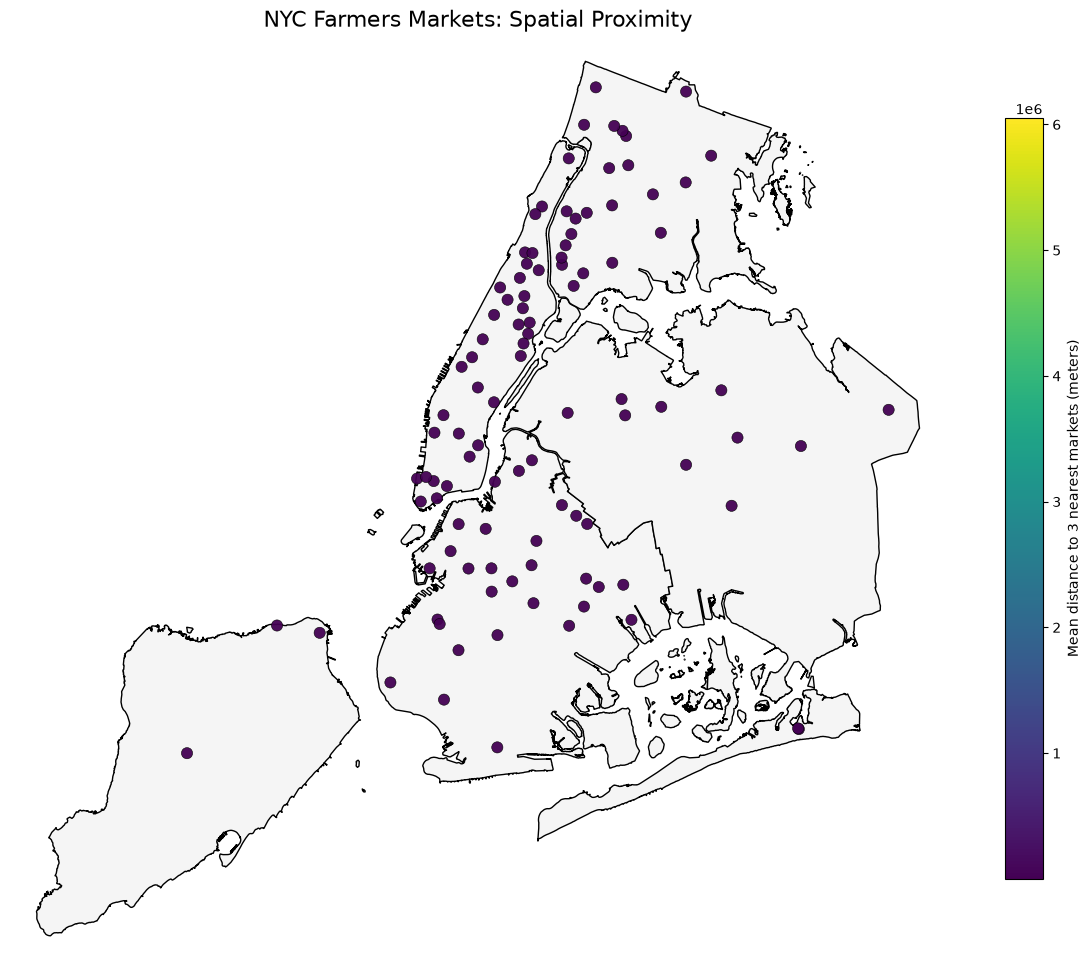

In [16]:

fig, ax = plt.subplots(figsize=(12, 12))

# Borough boundaries underneath the points
boroughs_proj.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=1
)

# Farmers markets colored by proximity
markets_proj.plot(
    ax=ax,
    column="mean_3_nearest_m",
    cmap="viridis",
    markersize=65,
    alpha=0.95,
    edgecolor="black",
    linewidth=0.4,
    legend=True,
    legend_kwds={
        "label": "Mean distance to 3 nearest markets (meters)",
        "shrink": 0.65
    }
)

xmin, ymin, xmax, ymax = boroughs_proj.total_bounds

x_margin = (xmax - xmin) * 0.03
y_margin = (ymax - ymin) * 0.03

ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)

ax.set_title(
    "NYC Farmers Markets: Spatial Proximity",
    fontsize=16
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

In [17]:
# Load Recognized Shop Healthy Stores
stores_url = (
    "https://data.cityofnewyork.us/api/v3/views/"
    "ud4g-9x9z/export.csv?accessType=DOWNLOAD"
)

stores_df = pd.read_csv(stores_url)
print(stores_df.columns.tolist())
print(stores_df.head())


['Store Name', 'Street Address', 'Borough', 'Zip \nCode', 'Year Awarded', 'Program \nWave', 'Latitude', 'Longitude', 'Community Board', 'Council District', 'BIN', 'BBL', 'Census Tract (2020)', 'Neighborhood Tabulation Area (NTA) (2020)']
                 Store Name           Street Address Borough  Zip \nCode  \
0        Rivas Deli Grocery    651 East 183rd Street   Bronx       10458   
1                    C-Town  1761 Southern Boulevard   Bronx       10460   
2      La India Mini Market      1942 Marmion Avenue   Bronx       10460   
3              Los Hermanos         2019 Vyse Avenue   Bronx       10460   
4  Price Choice Food Market    820 East 180th Street   Bronx       10460   

   Year Awarded  Program \nWave   Latitude  Longitude  Community Board  \
0          2013               1  40.852568 -73.887484            206.0   
1          2013               1  40.837267 -73.888016            203.0   
2          2013               1  40.842942 -73.887136            206.0   
3        

In [18]:
stores_df["Latitude"] = pd.to_numeric(
    stores_df["Latitude"], errors="coerce"
)

stores_df["Longitude"] = pd.to_numeric(
    stores_df["Longitude"], errors="coerce"
)

# Remove records without coordinates
stores_df = stores_df.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Convert to a GeoDataFrame
stores = gpd.GeoDataFrame(
    stores_df,
    geometry=gpd.points_from_xy(
        stores_df["Longitude"],
        stores_df["Latitude"]
    ),
    crs="EPSG:4326"
)

stores_proj = stores.to_crs(epsg=2263)

print("Number of Shop Healthy stores:", len(stores_proj))


Number of Shop Healthy stores: 669


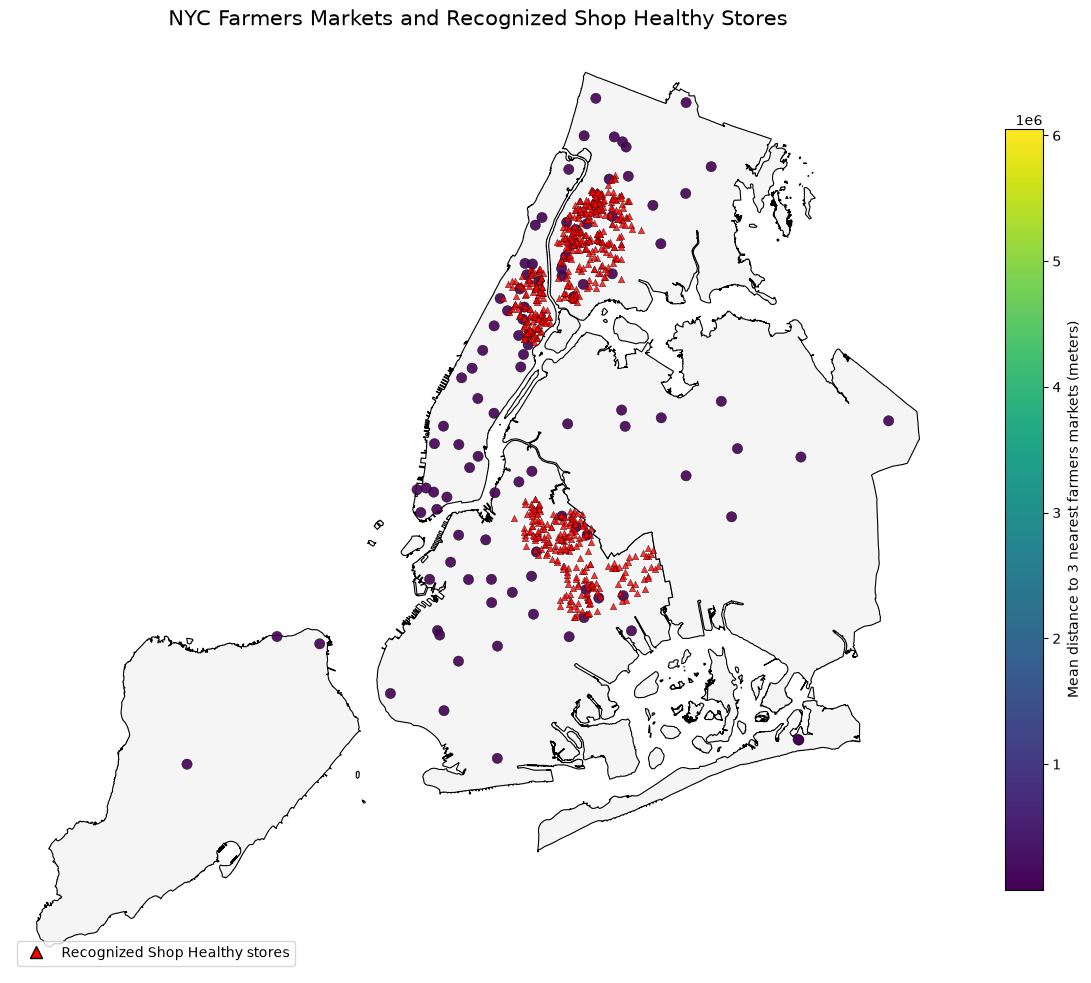

In [19]:

fig, ax = plt.subplots(figsize=(12, 12))

# 1. Borough boundaries
boroughs_proj.plot(
    ax=ax,
    color="whitesmoke",
    edgecolor="black",
    linewidth=0.8,
    zorder=1
)

# 2. Farmers markets: colored by proximity
markets_proj.plot(
    ax=ax,
    column="mean_3_nearest_m",
    cmap="viridis",
    markersize=55,
    edgecolor="black",
    linewidth=0.3,
    alpha=0.9,
    legend=True,
    legend_kwds={
        "label": "Mean distance to 3 nearest farmers markets (meters)",
        "shrink": 0.65
    },
    zorder=2
)

# 3. Recognized Shop Healthy stores: red triangles
stores_proj.plot(
    ax=ax,
    color="red",
    marker="^",
    markersize=22,
    edgecolor="black",
    linewidth=0.3,
    alpha=0.8,
    zorder=3
)

# Zoom to NYC borough boundaries
xmin, ymin, xmax, ymax = boroughs_proj.total_bounds

x_margin = (xmax - xmin) * 0.03
y_margin = (ymax - ymin) * 0.03

ax.set_xlim(xmin - x_margin, xmax + x_margin)
ax.set_ylim(ymin - y_margin, ymax + y_margin)

# Title and legend
ax.set_title(
    "NYC Farmers Markets and Recognized Shop Healthy Stores",
    fontsize=15,
    pad=15
)

from matplotlib.lines import Line2D

legend_items = [
    Line2D(
        [0], [0],
        marker="^",
        color="w",
        markerfacecolor="red",
        markeredgecolor="black",
        markersize=8,
        label="Recognized Shop Healthy stores"
    )
]

ax.legend(
    handles=legend_items,
    loc="lower left",
    frameon=True
)

ax.set_axis_off()
plt.tight_layout()
plt.show()


In [21]:

boroughs_web = boroughs.to_crs(epsg=3857)
markets_web = markets.to_crs(epsg=3857)
stores_web = stores.to_crs(epsg=3857)

print("Boroughs:", len(boroughs_web))
print("Farmers markets:", len(markets_web))
print("Shop Healthy stores:", len(stores_web))
print("Borough columns:", boroughs_web.columns.tolist())

Boroughs: 5
Farmers markets: 103
Shop Healthy stores: 669
Borough columns: [':id', ':version', ':created_at', ':updated_at', 'borocode', 'boroname', 'shape_area', 'shape_leng', 'geometry']


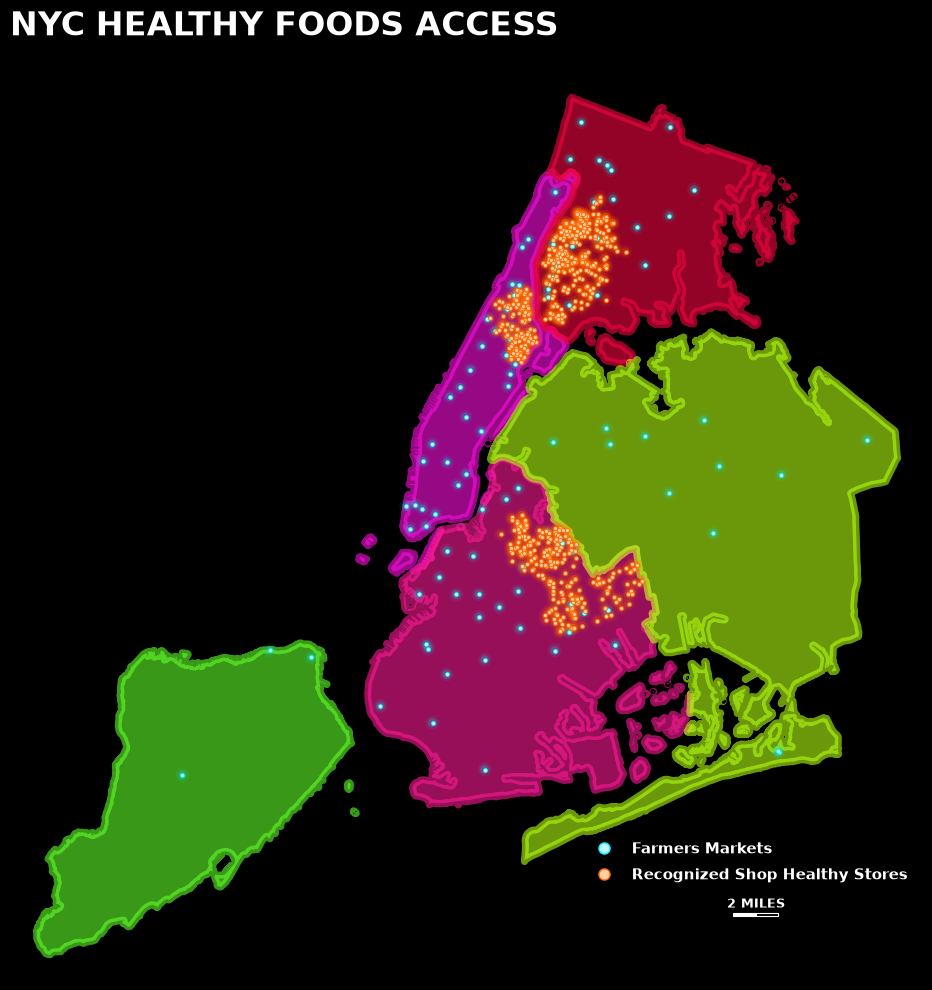

In [23]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

borough_colors = {
    "Manhattan": "#fb0fde",
    "Bronx": "#f60642",
    "Brooklyn": "#fd1a95",
    "Queens": "#b4fe11",
    "Staten Island": "#61fe29"
}

fig, ax = plt.subplots(figsize=(10, 10), facecolor="black")
ax.set_facecolor("black")

for borough, color in borough_colors.items():
    subset = boroughs_web[boroughs_web["boroname"] == borough]
    if not subset.empty:
        subset.plot(
            ax=ax,
            facecolor=color,
            edgecolor=color,
            alpha=0.6,
            linewidth=5,
            zorder=1
        )


markets_web.plot(
    ax=ax, color="#00F5FF", markersize=100,
    marker="o", alpha=0.08, edgecolor="none", zorder=4
)
markets_web.plot(
    ax=ax, color="#00F5FF", markersize=40,
    marker="o", alpha=0.22, edgecolor="none", zorder=5
)
markets_web.plot(
    ax=ax, color="#BFFFFF", markersize=8,
    marker="o", edgecolor="#00F5FF",
    linewidth=0.5, zorder=6
)

stores_web.plot(
    ax=ax, color="#FF6A00", markersize=100,
    marker="o", alpha=0.08, edgecolor="none", zorder=4
)
stores_web.plot(
    ax=ax, color="#FF6A00", markersize=40,
    marker="o", alpha=0.22, edgecolor="none", zorder=5
)
stores_web.plot(
    ax=ax, color="#FFD0A3", markersize=8,
    marker="o", edgecolor="#FF6A00",
    linewidth=0.6, zorder=6
)
# Title
ax.set_title(
    "NYC HEALTHY FOODS ACCESS",
    fontsize=24,
    fontweight="bold",
    color="white",
    pad=15,
    loc="left"
)

xmin, ymin, xmax, ymax = boroughs_web.total_bounds
xpad = (xmax - xmin) * 0.03
ypad = (ymax - ymin) * 0.03
ax.set_xlim(xmin - xpad, xmax + xpad)
ax.set_ylim(ymin - ypad, ymax + ypad)



legend_items = [
    Line2D(
        [0], [0], marker="o", linestyle="None",
        markerfacecolor="#BFFFFF",
        markeredgecolor="#00F5FF",
        markersize=8,
        label="Farmers Markets"
    ),
    Line2D(
        [0], [0], marker="o", linestyle="None",
        markerfacecolor="#FFD0A3",
        markeredgecolor="#FF6A00",
        markersize=8,
        label="Recognized Shop Healthy Stores"
    )
]

legend = ax.legend(
    handles=legend_items,
    loc="lower right",
    bbox_to_anchor=(0.99, 0.10),
    frameon=False,
    fontsize=11,
    handletextpad=0.8,
    labelspacing=0.7,
    borderaxespad=0
)

for text in legend.get_texts():
    text.set_color("white")
    text.set_fontweight("bold")
legend = ax.legend(
    handles=legend_items,
    loc="lower right",
    bbox_to_anchor=(0.99, 0.10),
    frameon=False,
    fontsize=11,
    handletextpad=0.8,
    labelspacing=0.7,
    borderaxespad=0
)

for text in legend.get_texts():
    text.set_color("white")
    text.set_fontweight("bold")


scale_meters = 2 * 1609.344

xmin, ymin, xmax, ymax = boroughs_web.total_bounds
xpad = (xmax - xmin) * 0.03
ypad = (ymax - ymin) * 0.03
x_range = xmax - xmin
y_range = ymax - ymin

bar_x = xmax - xpad - x_range * 0.16
bar_y = ymin + ypad + y_range * 0.015
bar_height = y_range * 0.003
half_bar = scale_meters / 2

ax.add_patch(Rectangle(
    (bar_x, bar_y),
    half_bar, bar_height,
    facecolor="white",
    edgecolor="white",
    linewidth=0.8,
    zorder=10
))

ax.add_patch(Rectangle(
    (bar_x + half_bar, bar_y),
    half_bar, bar_height,
    facecolor="black",
    edgecolor="white",
    linewidth=0.8,
    zorder=10
))

ax.text(
    bar_x + scale_meters / 2,
    bar_y + bar_height * 2,
    "2 MILES",
    ha="center",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    color="white",
    zorder=10
)

ax.set_aspect("equal")
ax.set_axis_off()
fig.tight_layout()
plt.show()

